# Medical Cost Prediction: Decision Tree Regression with EDA


End-to-end regression analysis on the Medical Cost Personal dataset. Includes univariate/bivariate EDA, interaction-based feature engineering, and a hyperparameter-tuned Decision Tree.

## 1. Setup & Import

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.tree import DecisionTreeRegressor, plot_tree
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

sns.set_style("whitegrid")
pd.set_option("display.float_format", "{:.2f}".format)

## 2. Data Loading and Initial Inspection

In [2]:
df = pd.read_csv('../data/insurance.csv')

In [3]:
df.head()

,age,sex,bmi,children,smoker,region,charges
0,19,female,27.90,0,yes,southwest,16884.92
1,18,male,33.77,1,no,southeast,1725.55
2,28,male,33.00,3,no,southeast,4449.46
3,33,male,22.70,0,no,northwest,21984.47
4,32,male,28.88,0,no,northwest,3866.86


In [4]:
df.shape

(1338, 7)

In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1338 entries, 0 to 1337
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       1338 non-null   int64  
 1   sex       1338 non-null   object 
 2   bmi       1338 non-null   float64
 3   children  1338 non-null   int64  
 4   smoker    1338 non-null   object 
 5   region    1338 non-null   object 
 6   charges   1338 non-null   float64
dtypes: float64(2), int64(2), object(3)
memory usage: 73.3+ KB


In [6]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
age,1338.00,39.21,14.05,18.00,27.00,39.00,51.00,64.00
bmi,1338.00,30.66,6.10,15.96,26.30,30.40,34.69,53.13
children,1338.00,1.09,1.21,0.00,0.00,1.00,2.00,5.00
charges,1338.00,13270.42,12110.01,1121.87,4740.29,9382.03,16639.91,63770.43


In [7]:
df.describe(include="object").T

,count,unique,top,freq
sex,1338,2,male,676
smoker,1338,2,no,1064
region,1338,4,southeast,364


## 3. Data Cleaning

### 3.1 Duplicate Detection and Removal

In [8]:
df.duplicated().sum()

np.int64(1)

In [9]:
df[df.duplicated(keep=False)]

,age,sex,bmi,children,smoker,region,charges
195,19,male,30.59,0,no,northwest,1639.56
581,19,male,30.59,0,no,northwest,1639.56


In [10]:
df = df.drop_duplicates().reset_index(drop=True)
print(f"New shape: {df.shape}")

New shape: (1337, 7)


## 4. Exploratory Data Analysis

### 4.1 Univariate Analysis — Numerical Features

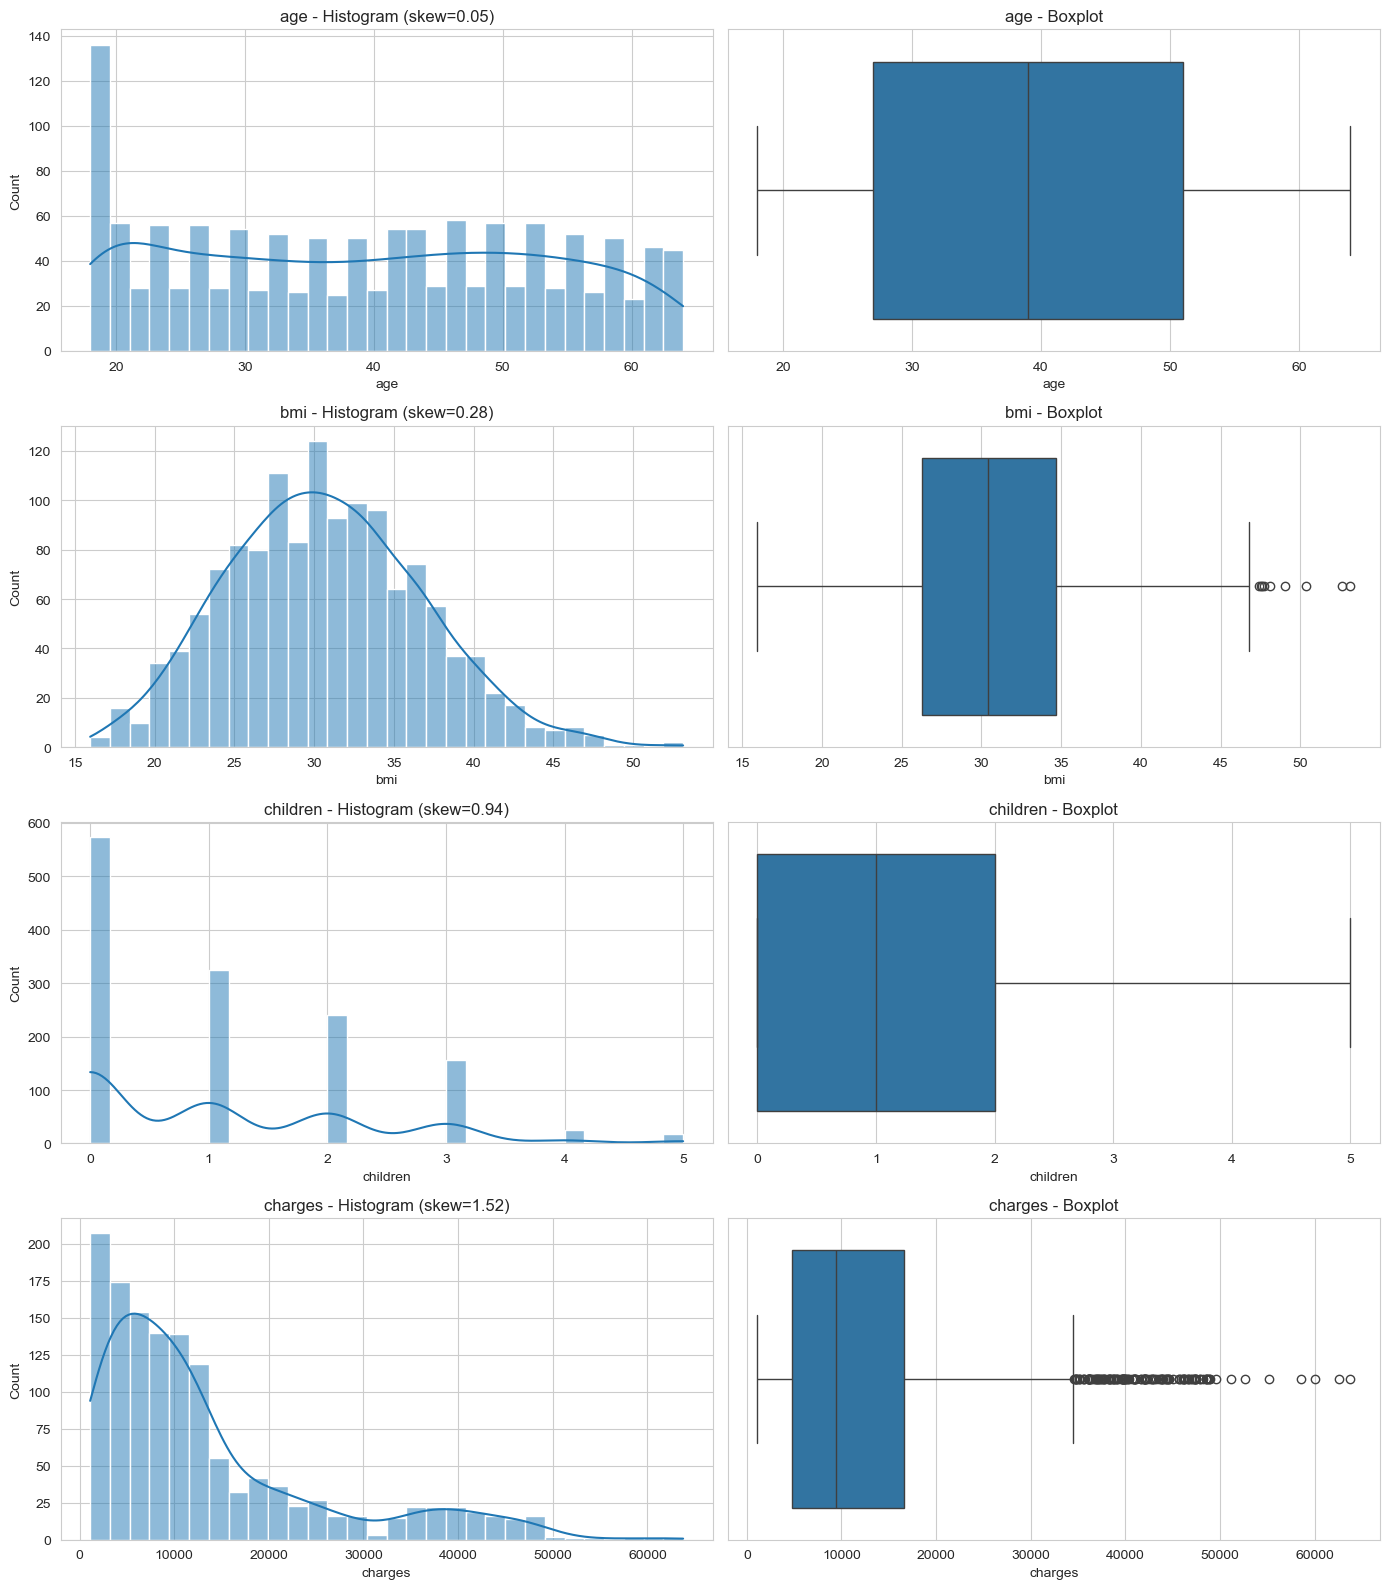

In [11]:
num_cols = ["age", "bmi", "children", "charges"]

fig, axes = plt.subplots(len(num_cols), 2, figsize=(14, 4*len(num_cols)))

for i, col in enumerate(num_cols):
    sns.histplot(df[col], kde=True, bins=30, ax=axes[i, 0])
    axes[i, 0].set_title(f"{col} - Histogram (skew={df[col].skew():.2f})")

    sns.boxplot(x=df[col], ax=axes[i, 1])
    axes[i, 1].set_title(f"{col} - Boxplot")

plt.tight_layout()
plt.show()

**Observations:** `charges` is highly right-skewed (skew=1.52), while `bmi` and `age` are approximately symmetric. Since Decision Tree is invariant to monotonic transformations, no log transformation is applied.

### 4.2 Univariate Analysis — Categorical Features

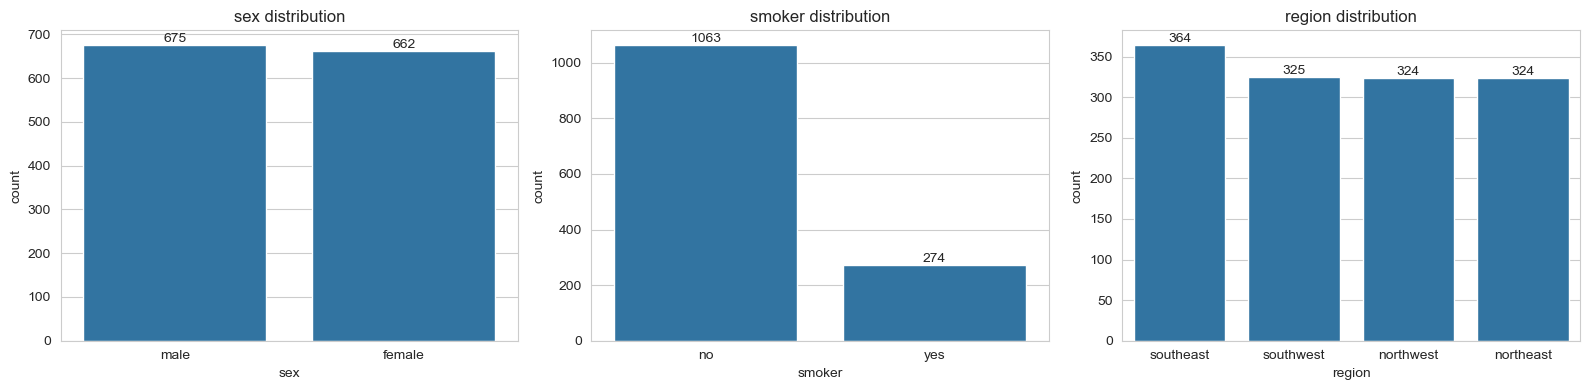

In [12]:
cat_cols = ["sex", "smoker", "region"]

fig, axes = plt.subplots(1, 3, figsize=(16, 4))

for i, col in enumerate(cat_cols):
    sns.countplot(data=df, x=col, ax=axes[i], 
                  order=df[col].value_counts().index)
    axes[i].set_title(f"{col} distribution")
    for container in axes[i].containers:
        axes[i].bar_label(container)

plt.tight_layout()
plt.show()

In [13]:
for col in cat_cols:
    print(f"\n{col}:")
    print(df[col].value_counts(normalize=True).round(3))


sex:
sex
male     0.51
female   0.49
Name: proportion, dtype: float64

smoker:
smoker
no    0.80
yes   0.20
Name: proportion, dtype: float64

region:
region
southeast   0.27
southwest   0.24
northwest   0.24
northeast   0.24
Name: proportion, dtype: float64


**Observations:** `sex` is balanced, `smoker` is imbalanced (~80% non-smoker), and `region` is distributed roughly evenly across four levels.

### 4.3 Bivariate Analysis — Categorical vs Target

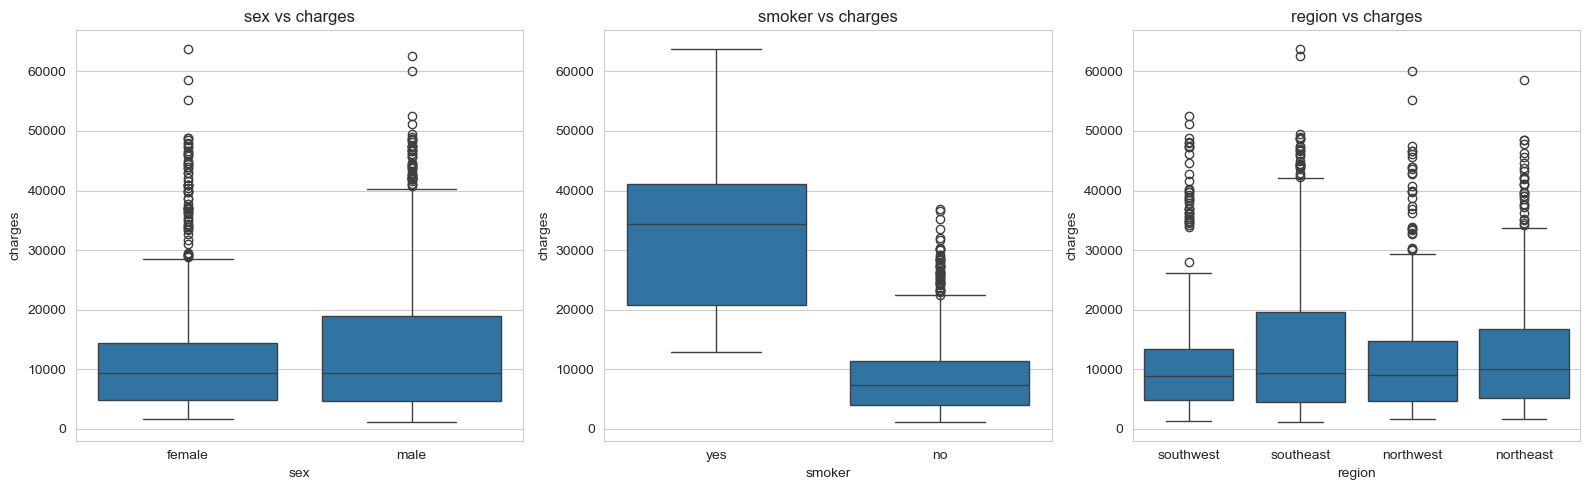

In [14]:
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

for i, col in enumerate(cat_cols):
    sns.boxplot(data=df, x=col, y="charges", ax=axes[i])
    axes[i].set_title(f"{col} vs charges")

plt.tight_layout()
plt.show()

**Observations:** `smoker` shows a dramatic effect on `charges` — the medians of the two groups are separated by a wide margin. `sex` and `region` show only marginal differences.

### 4.4 Bivariate Analysis — Numerical vs Target

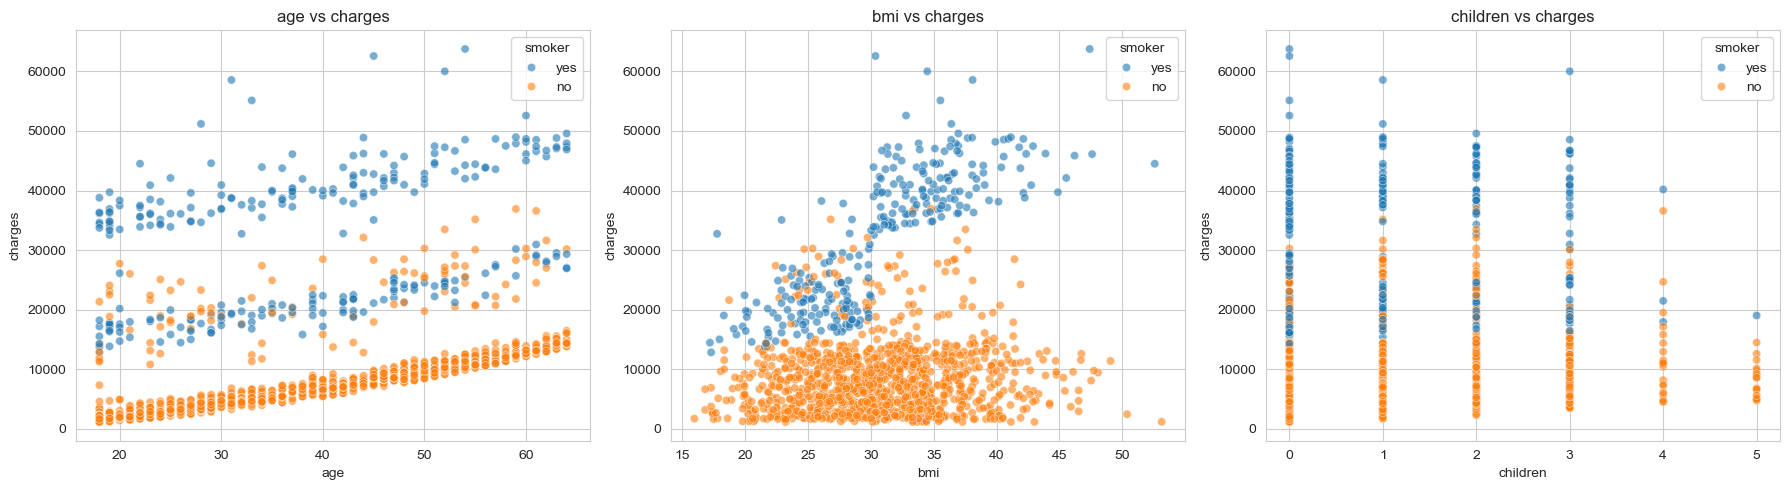

In [15]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for i, col in enumerate(["age", "bmi", "children"]):
    sns.scatterplot(data=df, x=col, y="charges", 
                    hue="smoker", alpha=0.6, ax=axes[i])
    axes[i].set_title(f"{col} vs charges")

plt.tight_layout()
plt.show()

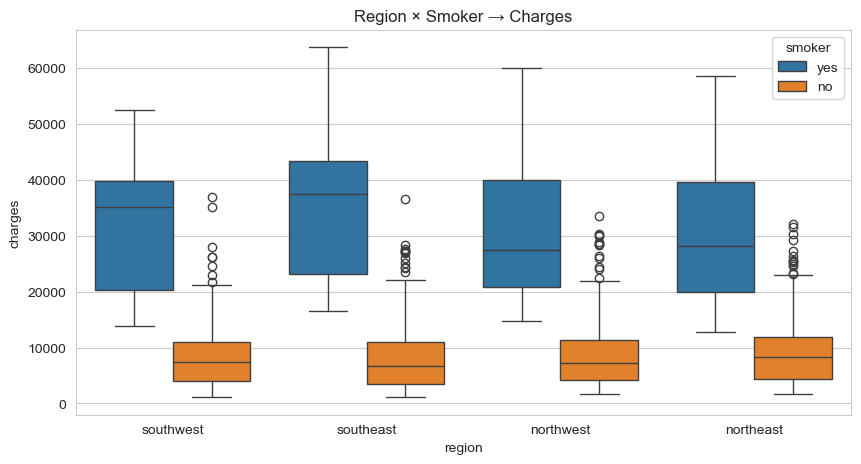

In [16]:
plt.figure(figsize=(10, 5))
sns.boxplot(data=df, x="region", y="charges", hue="smoker")
plt.title("Region × Smoker → Charges")
plt.show()

**Observations:** `age` shows three visible bands, driven by smoking status and BMI. `bmi` alone has a weak linear relationship with `charges`, but combined with `smoker`, a strong non-linear pattern emerges. 

### 4.5 Correlation Analysis

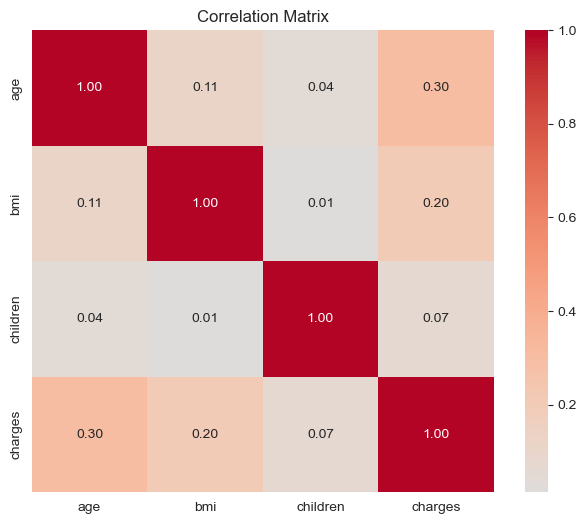

In [17]:
plt.figure(figsize=(8, 6))
sns.heatmap(df[num_cols].corr(), annot=True, cmap="coolwarm", 
            center=0, fmt=".2f", square=True)
plt.title("Correlation Matrix")
plt.show()

**Observations:** Linear correlations with `charges` are moderate at best (`age`: 0.30, `bmi`: 0.20). This is expected — the strongest relationships in this dataset are non-linear and interaction-driven, which Decision Trees are well suited to capture.

## 5. Feature Engineering

Three engineered features are added based on EDA findings:

- `bmi_category`: standard medical BMI classes (underweight, normal, overweight, obese)
- `risk_group`: interaction of `smoker` and BMI-obese threshold, motivated by Section 4.4
- `has_children`: binary flag for having any children

In [18]:
df["bmi_category"] = pd.cut(df["bmi"], 
                            bins=[0, 18.5, 25, 30, 100],
                            labels=["underweight", "normal", "overweight", "obese"])


In [19]:
conditions = [
    (df["smoker"] == "yes") & (df["bmi"] >= 30),
    (df["smoker"] == "yes") & (df["bmi"] < 30),
    (df["smoker"] == "no")  & (df["bmi"] >= 30),
    (df["smoker"] == "no")  & (df["bmi"] < 30),
]

choices = ["smoker_obese", "smoker_normal", 
           "nonsmoker_obese", "nonsmoker_normal"]

df["risk_group"] = np.select(conditions, choices, default="unknown")

unknown_count = (df["risk_group"] == "unknown").sum()
print(f"Unknown risk group count: {unknown_count}")

Unknown risk group count: 0


In [20]:
df["has_children"] = (df["children"] > 0).astype(int)

In [21]:
df.head()

,age,sex,bmi,children,smoker,region,charges,bmi_category,risk_group,has_children
0,19,female,27.90,0,yes,southwest,16884.92,overweight,smoker_normal,0
1,18,male,33.77,1,no,southeast,1725.55,obese,nonsmoker_obese,1
2,28,male,33.00,3,no,southeast,4449.46,obese,nonsmoker_obese,1
3,33,male,22.70,0,no,northwest,21984.47,normal,nonsmoker_normal,0
4,32,male,28.88,0,no,northwest,3866.86,overweight,nonsmoker_normal,0


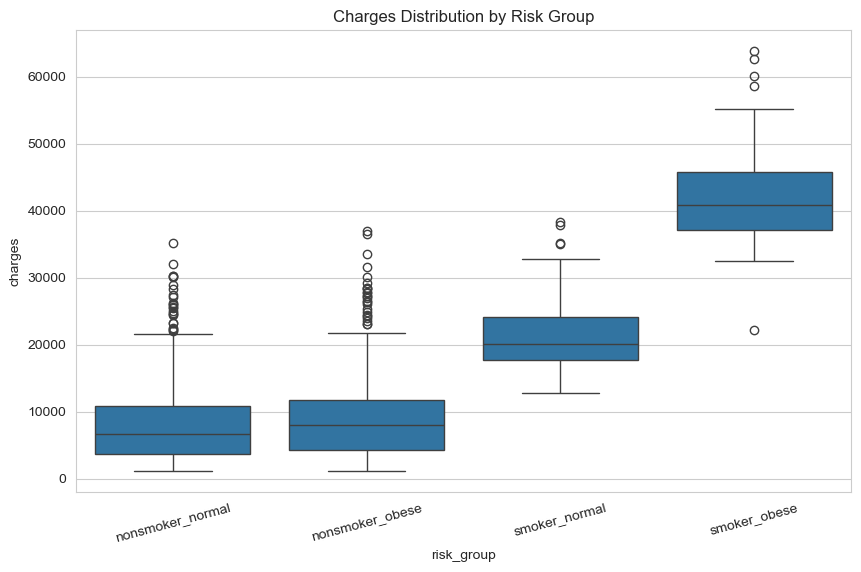

In [22]:
plt.figure(figsize=(10, 6))
sns.boxplot(data=df, x="risk_group", y="charges",
            order=["nonsmoker_normal", "nonsmoker_obese",
                   "smoker_normal", "smoker_obese"])
plt.xticks(rotation=15)
plt.title("Charges Distribution by Risk Group")
plt.show()

**Observations:** The four risk groups show clearly separated charge distributions. The `smoker_obese` group has the highest median, roughly three to four times that of `nonsmoker_normal`. This validates the interaction feature.

## 6. Preprocessing Pipeline

In [23]:
X = df.drop("charges", axis=1)
y = df['charges']

print("Features:", X.columns.tolist())
print("Shape:", X.shape)

Features: ['age', 'sex', 'bmi', 'children', 'smoker', 'region', 'bmi_category', 'risk_group', 'has_children']
Shape: (1337, 9)


In [24]:
categorical = ["sex", "smoker", "region", "bmi_category", "risk_group"]
numerical = ["age", "bmi", "children", "has_children"]

preprocessor = ColumnTransformer(
    transformers=[
        ("cat", OneHotEncoder(drop="first", handle_unknown="ignore"), categorical),
        ("num", "passthrough", numerical)
    ]
)

In [25]:
X_transformed = preprocessor.fit_transform(X)
print("Transformed shape:", X_transformed.shape)
print("Feature names:", preprocessor.get_feature_names_out())

Transformed shape: (1337, 15)
Feature names: ['cat__sex_male' 'cat__smoker_yes' 'cat__region_northwest'
 'cat__region_southeast' 'cat__region_southwest' 'cat__bmi_category_obese'
 'cat__bmi_category_overweight' 'cat__bmi_category_underweight'
 'cat__risk_group_nonsmoker_obese' 'cat__risk_group_smoker_normal'
 'cat__risk_group_smoker_obese' 'num__age' 'num__bmi' 'num__children'
 'num__has_children']


The preprocessor produces 15 columns from the original 9, applying one-hot encoding to categorical features while passing numerical features through unchanged. Scaling is omitted because Decision Trees are invariant to feature scale.

## 7. Train-Test Split

In [26]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

print(f"Train shape: {X_train.shape}")
print(f"Test shape:  {X_test.shape}")
print(f"y_train mean: {y_train.mean():.0f}")
print(f"y_test mean:  {y_test.mean():.0f}")

Train shape: (1069, 9)
Test shape:  (268, 9)
y_train mean: 13030
y_test mean:  14272


## 8. Baseline Model

In [27]:
# Pipeline: preprocessor + model
baseline_pipe = Pipeline([
    ("prep", preprocessor),
    ("model", DecisionTreeRegressor(random_state=42))
])

# Fit
baseline_pipe.fit(X_train, y_train)

# Predictions
y_train_pred = baseline_pipe.predict(X_train)
y_test_pred = baseline_pipe.predict(X_test)

# Metrics
print("=" * 50)
print("BASELINE DECISION TREE (default params)")
print("=" * 50)
print(f"Train R²:   {r2_score(y_train, y_train_pred):.4f}")
print(f"Test R²:    {r2_score(y_test, y_test_pred):.4f}")
print(f"Train RMSE: {np.sqrt(mean_squared_error(y_train, y_train_pred)):.0f}")
print(f"Test RMSE:  {np.sqrt(mean_squared_error(y_test, y_test_pred)):.0f}")
print(f"Train MAE:  {mean_absolute_error(y_train, y_train_pred):.0f}")
print(f"Test MAE:   {mean_absolute_error(y_test, y_test_pred):.0f}")

BASELINE DECISION TREE (default params)
Train R²:   1.0000
Test R²:    0.8162
Train RMSE: 0
Test RMSE:  5812
Train MAE:  0
Test MAE:   2698


In [28]:
tree_model = baseline_pipe.named_steps["model"]
print(f"Tree depth: {tree_model.get_depth()}")
print(f"Number of leaves:  {tree_model.get_n_leaves()}")
print(f"Train sample size: {len(X_train)}")

Tree depth: 19
Number of leaves:  1069
Train sample size: 1069


**Observations:** The baseline model overfits — train R² is 1.00 while test R² is 0.82. The number of leaves equals the number of training samples, meaning the tree memorized each row into its own leaf. This motivates hyperparameter tuning in the next section.

## 9. Hyperparameter Tuning

In [29]:
tuning_pipe = Pipeline([
    ("prep", preprocessor),
    ("model", DecisionTreeRegressor(random_state=42))
])

param_grid = {
    "model__max_depth": [3, 5, 7, 10, 15, None],
    "model__min_samples_split": [2, 5, 10, 20],
    "model__min_samples_leaf": [1, 5, 10, 20],
    "model__criterion": ["squared_error", "friedman_mse"]
}

grid = GridSearchCV(
    tuning_pipe,
    param_grid,
    cv=5,
    scoring="r2",
    n_jobs=-1,
    verbose=1
)

grid.fit(X_train, y_train)

print(f"\nBest Parameters: {grid.best_params_}")
print(f"Best CV Score:     {grid.best_score_:.4f}")

Fitting 5 folds for each of 192 candidates, totalling 960 fits

Best Parameters: {'model__criterion': 'squared_error', 'model__max_depth': 5, 'model__min_samples_leaf': 10, 'model__min_samples_split': 2}
Best CV Score:     0.8340


## 10. Final Model Evaluation

In [30]:
best_model = grid.best_estimator_

y_train_pred = best_model.predict(X_train)
y_test_pred = best_model.predict(X_test)

print("=" * 50)
print("TUNED DECISION TREE")
print("=" * 50)
print(f"Train R²:   {r2_score(y_train, y_train_pred):.4f}")
print(f"Test R²:    {r2_score(y_test, y_test_pred):.4f}")
print(f"Train RMSE: {np.sqrt(mean_squared_error(y_train, y_train_pred)):.0f}")
print(f"Test RMSE:  {np.sqrt(mean_squared_error(y_test, y_test_pred)):.0f}")
print(f"Train MAE:  {mean_absolute_error(y_train, y_train_pred):.0f}")
print(f"Test MAE:   {mean_absolute_error(y_test, y_test_pred):.0f}")

TUNED DECISION TREE
Train R²:   0.8572
Test R²:    0.8964
Train RMSE: 4422
Test RMSE:  4364
Train MAE:  2523
Test MAE:   2599


In [31]:
# Tree structure
tuned_tree = best_model.named_steps["model"]
print(f"\nTree Depth: {tuned_tree.get_depth()}")
print(f"Number of Leaves:  {tuned_tree.get_n_leaves()}")


Tree Depth: 5
Number of Leaves:  22


**Observations:** After tuning, train R² dropped to 0.86 while test R² rose to 0.90, closing the train-test gap. The tree is now shallow (depth 5) and compact (~30 leaves) — smaller, more interpretable, and better at generalization.

## 11. Model Interpretation and Visualization

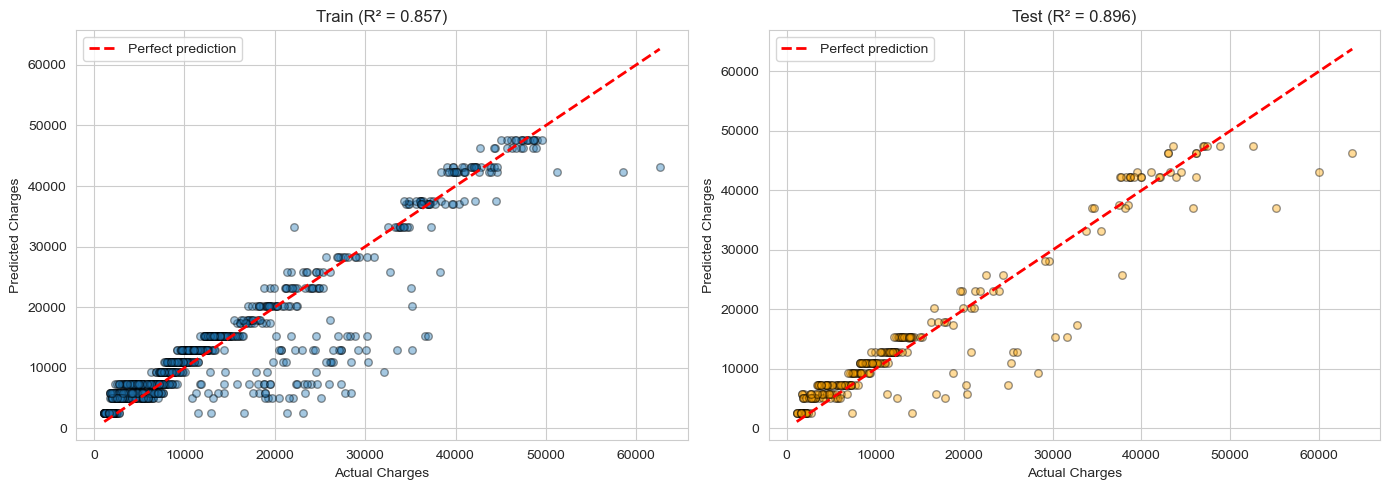

In [32]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].scatter(y_train, y_train_pred, alpha=0.4, edgecolor="k", s=30)
axes[0].plot([y_train.min(), y_train.max()],
             [y_train.min(), y_train.max()],
             "r--", lw=2, label="Perfect prediction")
axes[0].set_xlabel("Actual Charges")
axes[0].set_ylabel("Predicted Charges")
axes[0].set_title(f"Train (R² = {r2_score(y_train, y_train_pred):.3f})")
axes[0].legend()

axes[1].scatter(y_test, y_test_pred, alpha=0.4, edgecolor="k", s=30, color="orange")
axes[1].plot([y_test.min(), y_test.max()],
             [y_test.min(), y_test.max()],
             "r--", lw=2, label="Perfect prediction")
axes[1].set_xlabel("Actual Charges")
axes[1].set_ylabel("Predicted Charges")
axes[1].set_title(f"Test (R² = {r2_score(y_test, y_test_pred):.3f})")
axes[1].legend()

plt.tight_layout()
plt.show()

**Observations:** Predictions follow the diagonal line closely for low and 
mid-range charges. For high charges (mostly smokers), predictions spread away 
from the line and often fall below actual values — the model tends to predict 
lower than reality in this range.

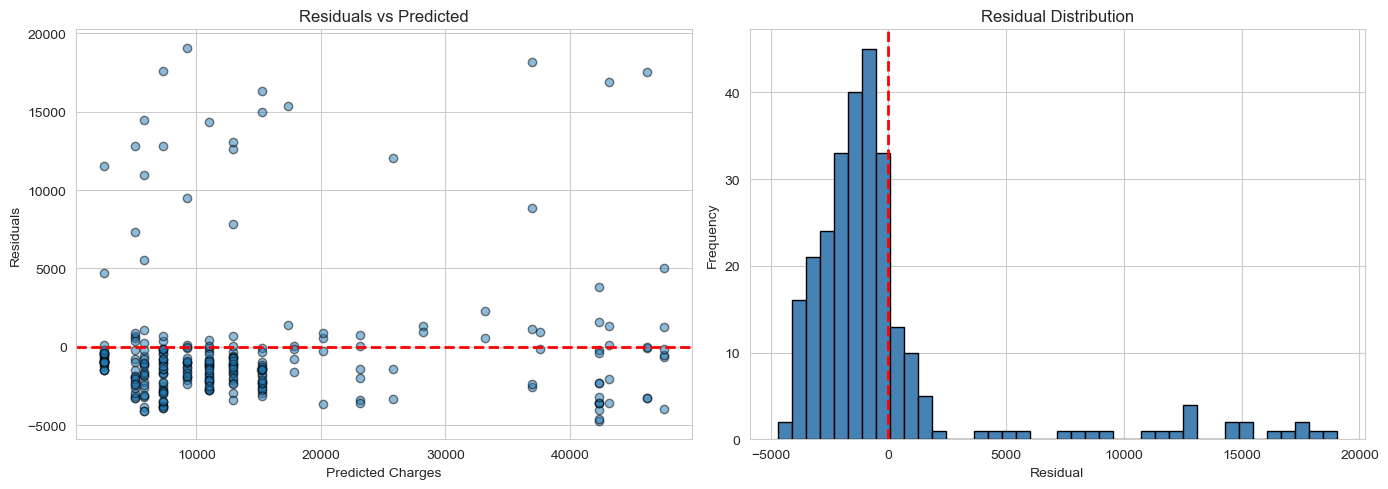

Residual mean: -175
Residual std:  4369


In [33]:
residuals = y_test - y_test_pred

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].scatter(y_test_pred, residuals, alpha=0.5, edgecolor="k")
axes[0].axhline(0, color="red", linestyle="--", lw=2)
axes[0].set_xlabel("Predicted Charges")
axes[0].set_ylabel("Residuals")
axes[0].set_title("Residuals vs Predicted")

axes[1].hist(residuals, bins=40, edgecolor="k", color="steelblue")
axes[1].axvline(0, color="red", linestyle="--", lw=2)
axes[1].set_xlabel("Residual")
axes[1].set_ylabel("Frequency")
axes[1].set_title("Residual Distribution")

plt.tight_layout()
plt.show()

print(f"Residual mean: {residuals.mean():.0f}")
print(f"Residual std:  {residuals.std():.0f}")

**Observations:** Residuals are approximately centered around zero with no strong systematic pattern. The distribution has a slight right tail, reflecting the model's difficulty with the highest-charge observations.

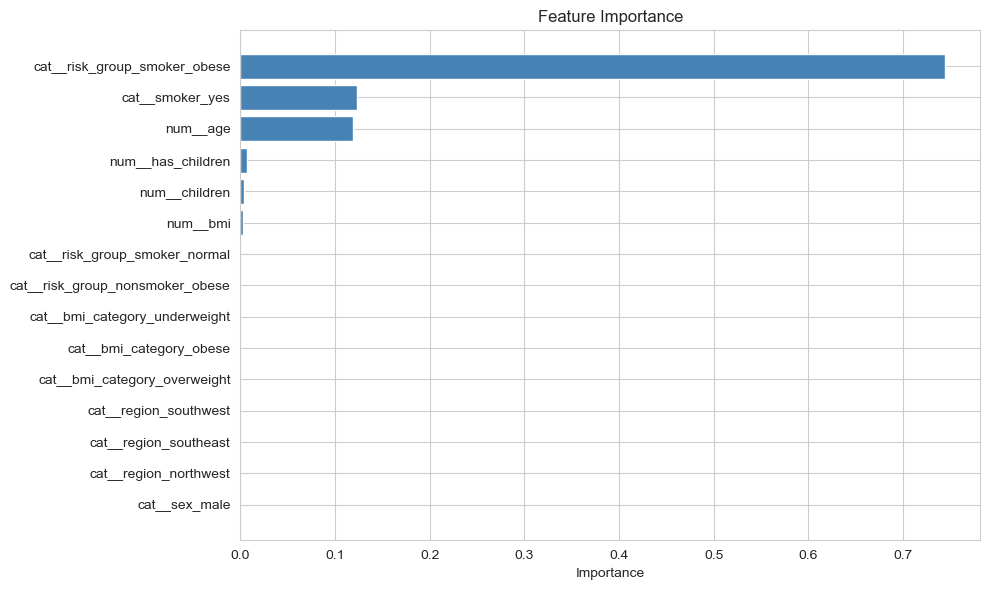

,feature,importance
10,cat__risk_group_smoker_obese,0.74
1,cat__smoker_yes,0.12
11,num__age,0.12
14,num__has_children,0.01
13,num__children,0.00
12,num__bmi,0.00
0,cat__sex_male,0.00
7,cat__bmi_category_underweight,0.00
5,cat__bmi_category_obese,0.00
6,cat__bmi_category_overweight,0.00


In [34]:
feature_names = best_model.named_steps["prep"].get_feature_names_out()
importances = best_model.named_steps["model"].feature_importances_

importance_df = pd.DataFrame({
    "feature": feature_names,
    "importance": importances
}).sort_values("importance", ascending=True)

plt.figure(figsize=(10, 6))
plt.barh(importance_df["feature"], importance_df["importance"], color="steelblue")
plt.xlabel("Importance")
plt.title("Feature Importance")
plt.tight_layout()
plt.show()

importance_df.sort_values("importance", ascending=False).head(10)

**Observations:** `smoker` and BMI-related features dominate. This confirms the EDA findings: smoking status is the primary driver of insurance charges, with BMI acting as a secondary amplifier — especially for smokers.

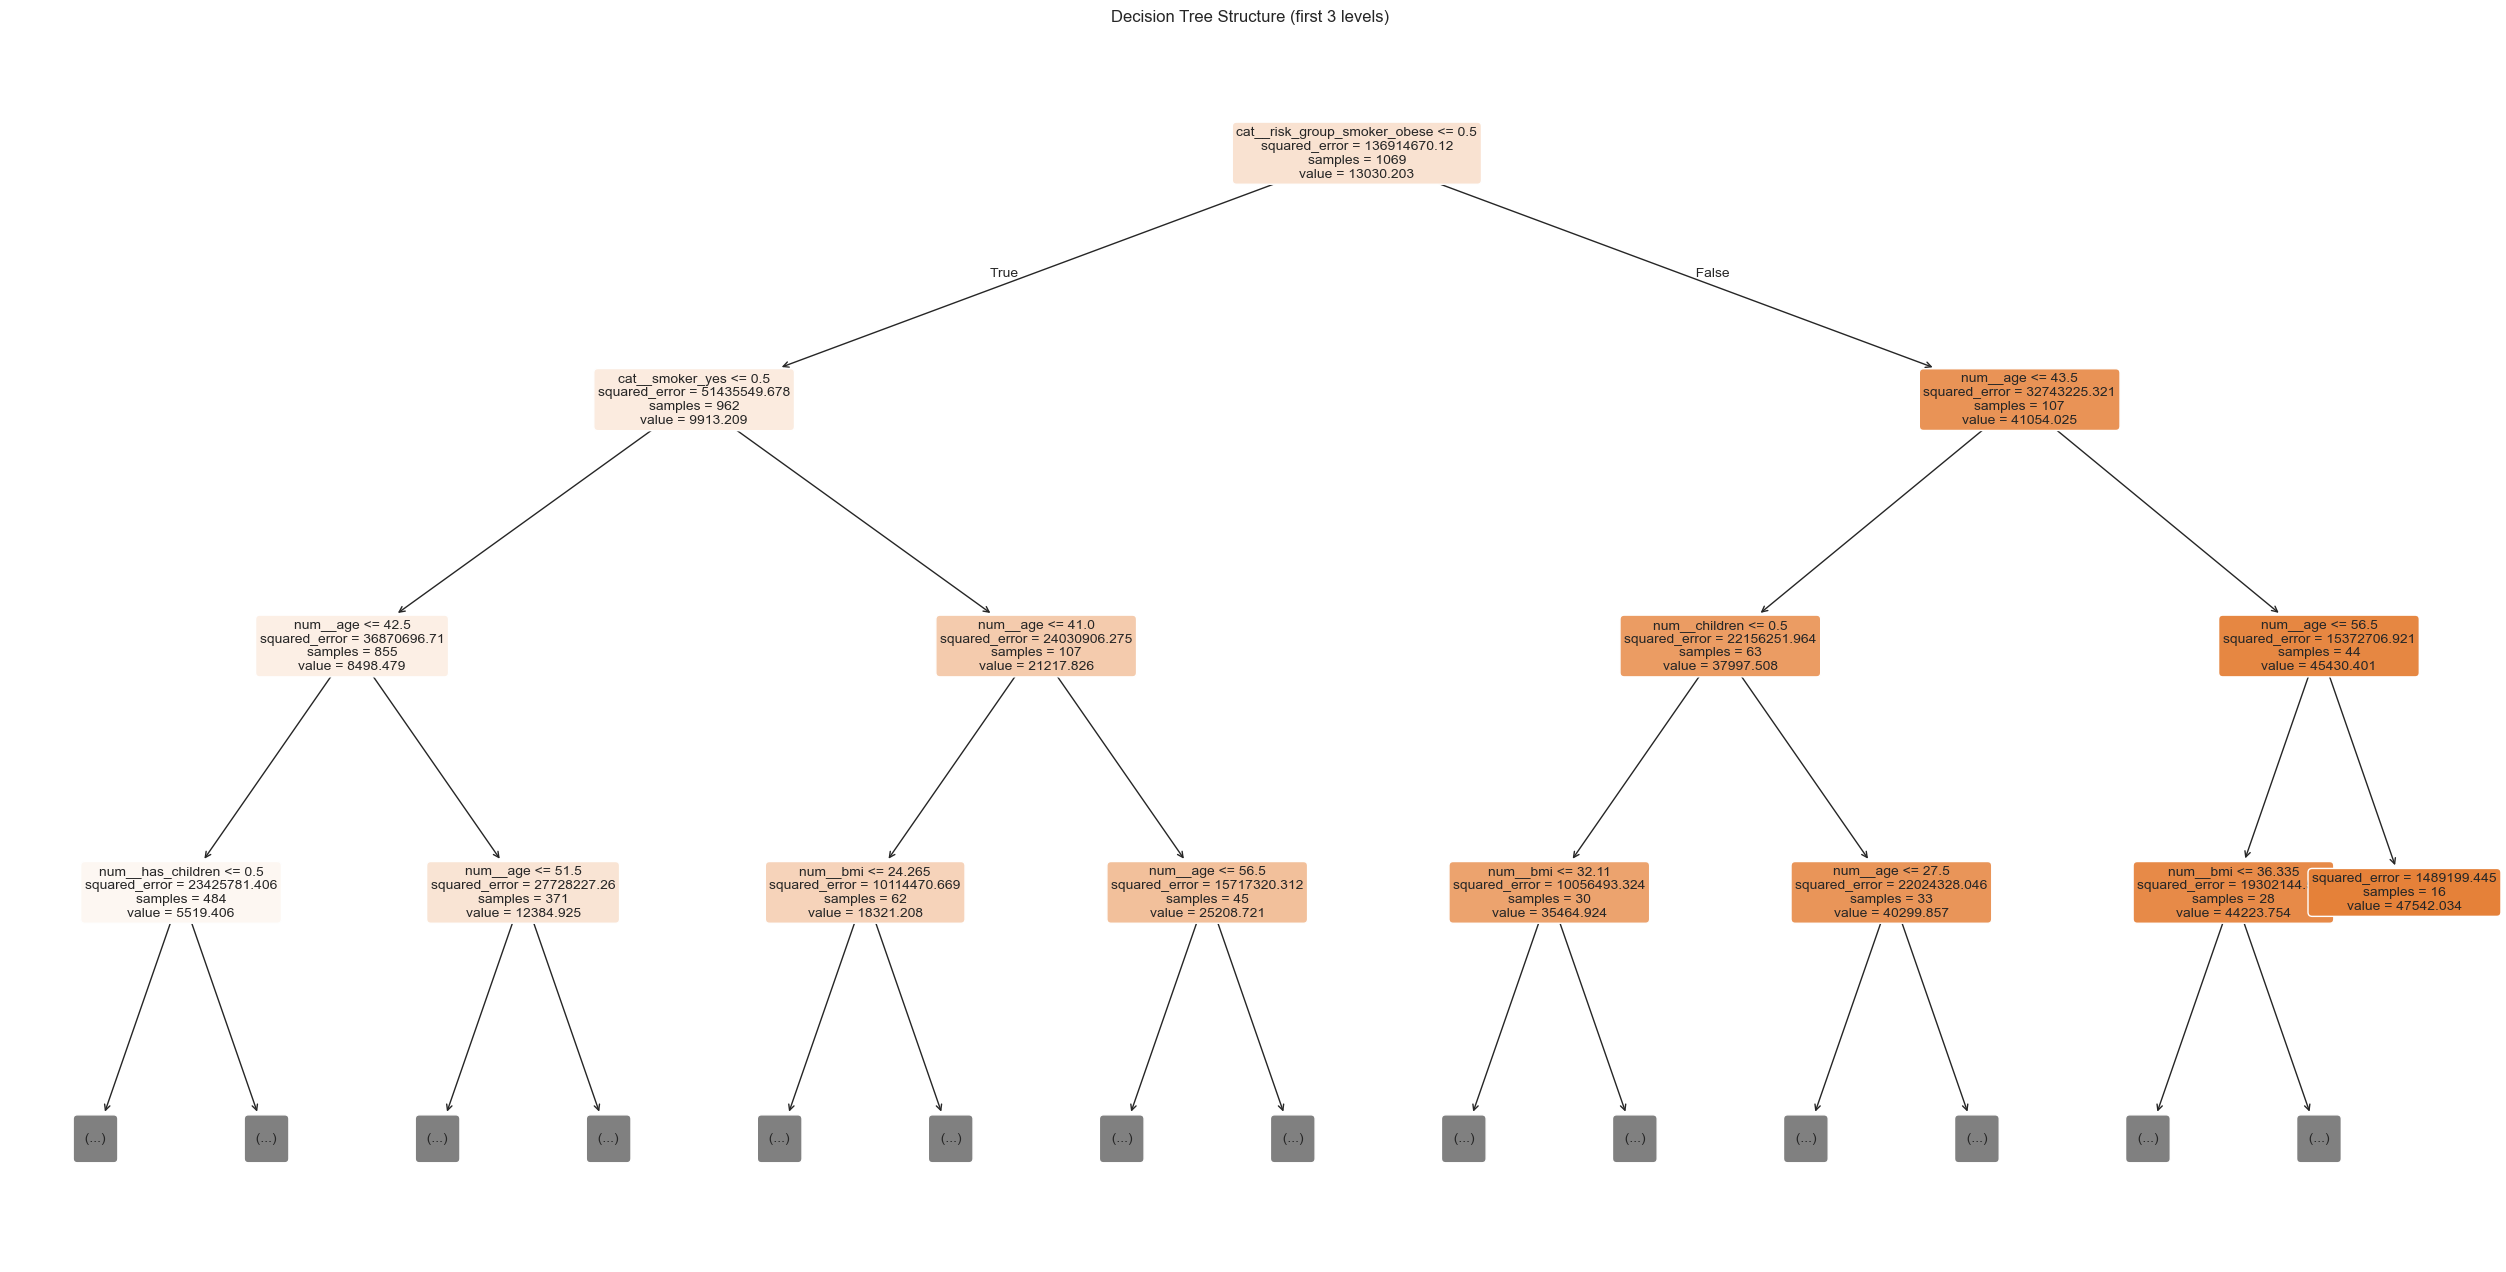

In [35]:
plt.figure(figsize=(32, 16))
plot_tree(best_model.named_steps["model"],
          feature_names=feature_names,
          filled=True,
          rounded=True,
          fontsize=10,
          max_depth=3)
plt.title("Decision Tree Structure (first 3 levels)")
plt.show()

**Observations:** The root split is on `smoker`, dividing the population into two groups with fundamentally different charge distributions. Subsequent splits use `age` and `bmi`, mirroring the interaction structure identified during EDA.

## 12. Conclusion

This study built a Decision Tree Regression model to predict individual medical insurance charges.

**Key findings:**
- Smoking status is the single strongest predictor of charges, with BMI amplifying its effect — captured explicitly by the engineered `risk_group` feature.
- The baseline tree overfit severely (train R² 1.00 vs test R² 0.82). Hyperparameter tuning produced a compact model (depth 5, ~30 leaves) with test R² 0.90 and RMSE ≈ 4400.
- The final model is both more accurate and more interpretable — its root split on smoking status directly reflects the dominant pattern observed during EDA.

**Limitations and next steps:**
- A single Decision Tree has high variance; ensemble methods (Random Forest, Gradient Boosting) would likely reduce test RMSE further.
- The dataset is small (~1300 rows) and the target is heavily right-skewed; robustness could be assessed with repeated cross-validation across multiple random seeds.
- High-charge observations (mostly smokers) are systematically under-predicted, as seen in the residual analysis; additional features or a model with smoother predictions could help in this range.